### 컬럼

* order_id                 : 주문 ID
* product_id               : 상품 ID
* category                 : 상품 카테고리 (채소 / 과일 / 가공식품 / 우유 / 축산)
* sku_option               : 옵션 정보 (동일 SKU/동일 옵션 판단용)
* worker_type              : 작업자 유형 (experienced / novice)
* is_peak_time             : 피크 시간 여부 (0/1) — 11~13시 / 17~19시

* cancel_reason            : 취소 사유 (normal_cancel / wrong_pick / miss_pick)
* cancel_time              : 취소 발생 시점 (주문 후 1~30분 이내)

* stock_location           : 재고 위치 (A~E 구역 + 번호)
* location_known           : 재고 위치 정보 존재 여부 (0/1)

* process_time             : 전산 처리 완료 시점
* process_delay_min        : 처리 지연 시간 (분) — 0~100분 균등 분포

* restock_flag             : 재고 반영 여부 (0/1)
                             - normal_cancel → 1 고정
                             - miss_pick     → 0 고정 (상품 없음)
                             - wrong_pick    → 지연 시간에 따라 확률적 결정
* inspection_flag          : 검수 여부 (0/1) — wrong_pick + 재고 반영된 경우만 대상

* search_start_time        : 재사용 탐색 시작 시점 (process_time 기준)
* search_end_time          : 재사용 탐색 종료 시점
* search_time_min          : 탐색 시간 (분)
  - location_known=1 → 0~1분
  - location_known=0 → 1~3분

* reused_flag              : 재사용 성공 여부 (0/1) — wrong_pick + 검수 통과 시만 대상
* additional_cancel_flag   : 추가 취소 발생 여부 (0/1) — 재사용 실패 시 확률적 발생

### 분석 단계

* STEP 1. 파라미터 설정
  - 시뮬레이션 규모, 취소 사유 비율, 작업자 구성, 카테고리별 재사용 확률 등 전역 변수 정의

* STEP 2. 주문 데이터 생성
  - N_ORDERS 건의 주문 생성 (order_id, product_id, category, sku_option, order_time, is_peak_time)

* STEP 3. 취소 발생 & cancel_reason 부여
  - 전체 주문 중 CANCEL_RATE 비율로 취소 샘플링
  - 작업자 숙련도 + 피크 시간 + 오진열 여부 반영해 cancel_reason 확률적 결정
  - stock_location, location_known 생성

* STEP 4. 파생 컬럼 생성
  - process_delay_min / process_time 생성
  - restock_flag, inspection_flag, reused_flag, additional_cancel_flag 순차 결정
  - search_start_time, search_end_time, search_time_min 생성
  - 최종 컬럼 순서 정렬

* STEP 5. 1단계 분석 — 전체 현황
  - 전체/운영 취소 건수, 재사용률, 추가 취소 발생률 출력
  - 취소 사유별 건수 bar chart

* STEP 6. 2단계 분석 — 지연 분석
  - process_delay_min 구간화 후 구간별 재사용률 비교
  - 30분 기준 재사용률 차이 확인 (bar chart + scatter)

* STEP 7. 3단계 분석 — 사유 분석
  - cancel_reason별 재사용률 / 추가 취소율 비교
  - wrong_pick 상세 수치 출력

* STEP 8. 4단계 분석 — 카테고리 분석
  - category별 취소 건수 / 재사용률 / 추가 취소율 비교 (bar chart 3종)

* STEP 9. 5단계 분석 — 운영 개선 시뮬레이션
  - 개선 후 데이터 재생성 (지연 단축 + location_known 상향)
  - 개선 전/후 재사용률, 추가 취소율, 평균 탐색 시간 비교 테이블 + 그룹 bar chart

* STEP 10. 저장
  - simulation_data.csv / simulation_improved.csv → Google Drive 저장

In [ ]:
# 한글 폰트 설치 (최초 1회만 실행)
!apt-get install -y fonts-nanum
import matplotlib.font_manager as fm
fm._load_fontmanager(try_read_cache=False)

import matplotlib
matplotlib.rcParams['font.family'] = 'NanumGothic'
matplotlib.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 2 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 1s (11.4 MB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 118194 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...


## **STEP1 - 라이브러리 & 파라미터**

In [ ]:
# =============================================
# STEP 1: 라이브러리 & 파라미터
# =============================================
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import random
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'NanumGothic'
# TODO: 한글 폰트 미설치 시 아래 실행 후 런타임 재시작
# !apt-get install -y fonts-nanum
# import matplotlib; matplotlib.font_manager._load_fontmanager(try_read_cache=False)

np.random.seed(42)
random.seed(42)

# ── 시뮬레이션 규모 ──────────────────────────
N_ORDERS    = 50000
CANCEL_RATE = 0.10   # 전체 주문 대비 취소율 고정

# ── 취소 유형 비율 (전체 취소 기준) ──────────
CANCEL_TYPE_WEIGHTS = {
    '단순취소': 0.70,
    '운영취소': 0.30,
}

# ── 운영취소 내 사유 비율 ─────────────────────
# 전체 취소 대비: 오집 18% / 미집 9% / 집품파손 1.5% / 리빈파손 1.5%
CANCEL_REASON_WEIGHTS = {
    '오집':     0.60,
    '미집':     0.30,
    '집품파손': 0.05,
    '리빈파손': 0.05,
}

# ── 작업자 구성 ──────────────────────────────
WORKER_EXPERIENCED_RATIO = 0.67
BASE_ERROR_EXPERIENCED   = 0.01
BASE_ERROR_NOVICE        = 0.0625

# ── 카테고리 ─────────────────────────────────
CATEGORIES       = ['채소', '과일', '가공식품', '우유', '축산']
CATEGORY_WEIGHTS = [0.20, 0.20, 0.30, 0.15, 0.15]
# TODO: 실제 카테고리별 취급 비중으로 교체

# ── 카테고리별 재사용 확률 (오집 기준) ────────
REUSE_PROB = {
    '채소':     0.30,
    '과일':     0.35,
    '가공식품': 0.80,
    '우유':     0.55,
    '축산':     0.50,
}
# TODO: 실제 운영 데이터로 검증 후 보정

# ── 처리 지연 임계값 ─────────────────────────
DELAY_THRESHOLD_MIN = 30

# ── 시뮬레이션 기간 ──────────────────────────
START_DATE = datetime(2024, 1, 1, 8, 0, 0)
SIM_DAYS   = 90

# ==========================================================
# [수정] 처리 방식별 처리 속도 파라미터
# - 기존(수동)  : 작업자가 직접 취소 처리 → 60분당 약 120건
# - 자동화      : 프로그램이 취소 처리    → 60분당 약 400건
# ==========================================================
MANUAL_THROUGHPUT    = 120   # 수동 처리: 60분당 처리 건수
AUTOMATED_THROUGHPUT = 400   # 자동화 처리: 60분당 처리 건수

# 건당 처리 소요 시간 (분)
MANUAL_TIME_PER_CASE    = round(60 / MANUAL_THROUGHPUT, 2)     # ≒ 0.5분/건
AUTOMATED_TIME_PER_CASE = round(60 / AUTOMATED_THROUGHPUT, 2)  # ≒ 0.15분/건

# [수정] 기존(수동) 처리 시 탐색 현장 검증 추가 딜레이
# - 기존 수동 처리에서는 별도 inspection(검수) 단계가 없음
# - 대신 탐색 시 작업자가 현장에서 직접 상품 상태를 확인
# - 이 현장 확인 시간을 search_time_min 에 추가 가중
MANUAL_ONSITE_VERIFY_RANGE = (0.5, 2.0)  # 현장 검증 추가 소요 시간 범위 (분)


## **STEP2 - 주문 데이터 생성**

In [ ]:
# =============================================
# STEP 2: 전체 주문 데이터 생성
# =============================================

def generate_orders(n):
    order_times = []
    for _ in range(n):
        day    = random.randint(0, SIM_DAYS - 1)
        hour   = random.choices(range(8, 23),
                                weights=[3,4,6,8,8,7,6,7,8,9,8,7,6,5,4], k=1)[0]
        minute = random.randint(0, 59)
        order_times.append(START_DATE + timedelta(days=day, hours=hour-8, minutes=minute))
    # TODO: 실제 주문 시간 분포로 교체

    # 피크 타임: 11~13시 / 17~19시
    # TODO: 실제 운영 피크 시간대 정의로 교체
    is_peak = [1 if t.hour in [11,12,13,17,18,19] else 0 for t in order_times]

    return pd.DataFrame({
        'order_id':     [f'ORD-{str(i).zfill(6)}' for i in range(1, n+1)],
        'product_id':   [f'PRD-{str(random.randint(1,500)).zfill(4)}' for _ in range(n)],
        'category':     random.choices(CATEGORIES, weights=CATEGORY_WEIGHTS, k=n),
        'sku_option':   [f'OPT-{random.randint(1,3):02d}' for _ in range(n)],
        'order_time':   order_times,
        'is_peak_time': is_peak,
    })

orders_df = generate_orders(N_ORDERS)
print(f"전체 주문 수: {len(orders_df):,}")

전체 주문 수: 50,000


## **STEP3 - 취소 발생&유형/사유 부여**

In [ ]:
# =============================================
# STEP 3: 취소 발생 & cancel_reason 부여
# =============================================

def assign_cancel_reason(row):
    """
    작업자 숙련도 + 피크 시간 + 오진열 여부 반영
    → 단순취소 / 운영취소(오집/미집/집품파손/리빈파손) 결정
    """
    is_exp  = random.random() < WORKER_EXPERIENCED_RATIO
    w_type  = '숙련자' if is_exp else '비숙련자'

    # 기본 오류율 + 피크 시간 추가 오류율
    err = BASE_ERROR_EXPERIENCED if is_exp else BASE_ERROR_NOVICE
    if row['is_peak_time']:
        err += random.uniform(0, 0.02) if is_exp else random.uniform(0, 0.04)

    # 오진열 이벤트 (약 5% 확률 발생)
    # TODO: 실제 오진열 발생률로 교체
    if random.random() < 0.05:
        wp = 0.20 if is_exp else 0.95
        if random.random() < wp:
            return w_type, '오집'

    # 오류율 기반 취소 유형 결정
    if random.random() < err:
        # 운영취소 → 사유 부여
        reason = random.choices(
            list(CANCEL_REASON_WEIGHTS.keys()),
            weights=list(CANCEL_REASON_WEIGHTS.values()),
            k=1
        )[0]
    else:
        # 단순취소
        reason = '단순취소'

    return w_type, reason


# 취소 샘플링
n_cancel  = int(N_ORDERS * CANCEL_RATE)
cancel_df = orders_df.sample(n=n_cancel, random_state=42).copy().reset_index(drop=True)

# 취소 발생 시점 (주문 후 1~30분)
cancel_df['cancel_time'] = cancel_df['order_time'].apply(
    lambda t: t + timedelta(minutes=random.randint(1, 30))
)

# 취소 사유 부여
result = cancel_df.apply(assign_cancel_reason, axis=1)
cancel_df['worker_type']   = [r[0] for r in result]
cancel_df['cancel_reason'] = [r[1] for r in result]

# 재고 위치 & 위치 정보 여부
# TODO: 실제 창고 구역 코드로 교체
cancel_df['stock_location'] = [
    f'{random.choice(["A","B","C","D","E"])}-{random.randint(1,20):02d}'
    for _ in range(len(cancel_df))
]
cancel_df['location_known'] = [
    1 if random.random() < 0.60 else 0
    for _ in range(len(cancel_df))
]

print("[ cancel_reason 분포 ]")
print(cancel_df['cancel_reason'].value_counts(normalize=True).round(3))

[ cancel_reason 분포 ]
cancel_reason
단순취소    0.944
오집      0.043
미집      0.011
리빈파손    0.001
집품파손    0.000
Name: proportion, dtype: float64


## **STEP4 - 처리 시간 & 재고 반영**

In [ ]:
# =============================================
# STEP 4: 처리 시간 & restock_flag & 오집 재고 풀
# =============================================

# 처리 지연 시간 (0~100분 균등 분포)
# TODO: 개선 후 시나리오는 STEP 11에서 0~30분으로 변경
cancel_df['process_delay_min'] = np.random.uniform(0, 100, len(cancel_df)).round(1)
cancel_df['process_time'] = cancel_df.apply(
    lambda r: r['cancel_time'] + timedelta(minutes=r['process_delay_min']), axis=1
)

# ==========================================================
# [수정] process_type 컬럼 추가
# - 기존 데이터(final_df)는 수동(manual) 처리 방식
# - 자동화(automated)는 STEP 11 개선 시뮬레이션에서 사용
# ==========================================================
cancel_df['process_type'] = 'manual'

# [수정] 처리 속도 지표 출력
print("[ 처리 방식별 속도 지표 ]")
print(f"  수동 처리   : 60분당 {MANUAL_THROUGHPUT}건  (건당 {MANUAL_TIME_PER_CASE}분)")
print(f"  자동화 처리 : 60분당 {AUTOMATED_THROUGHPUT}건  (건당 {AUTOMATED_TIME_PER_CASE}분)")
print(f"  처리 속도 향상 : {AUTOMATED_THROUGHPUT / MANUAL_THROUGHPUT:.1f}배")

def decide_restock(row):
    if row['cancel_reason'] == '단순취소':
        return 1   # 단순취소 → 재고 즉시 반영
    if row['cancel_reason'] == '미집':
        return 0   # 미집 → 상품 자체 없음 (오집 재고 풀에서 대체 탐색)
    if row['cancel_reason'] in ['집품파손', '리빈파손']:
        return 0   # 파손 → 재고 반영 불가
    # 오집: 처리 지연 길수록 반영 누락 확률 증가
    # TODO: 실제 누락률 데이터로 보정
    miss_prob = 0.05 + (row['process_delay_min'] / 100) * 0.30
    return 0 if random.random() < miss_prob else 1

cancel_df['restock_flag'] = cancel_df.apply(decide_restock, axis=1)

# ── 오집 재고 풀 생성 (미집 대체 재사용용) ────
# 오집 중 재고 반영된 건을 SKU별로 모아둠
wrong_pick_pool = (
    cancel_df[
        (cancel_df['cancel_reason'] == '오집') &
        (cancel_df['restock_flag'] == 1)
    ]
    .groupby(['product_id', 'sku_option'])
    .size()
    .reset_index(name='available_count')
)

print("\n[ restock_flag ]")
print(cancel_df['restock_flag'].value_counts())
print(f"\n오집 재고 풀 SKU 수: {len(wrong_pick_pool):,}")


[ 처리 방식별 속도 지표 ]
  수동 처리   : 60분당 120건  (건당 0.5분)
  자동화 처리 : 60분당 400건  (건당 0.15분)
  처리 속도 향상 : 3.3배

[ restock_flag ]
restock_flag
1    4898
0     102
Name: count, dtype: int64

오집 재고 풀 SKU 수: 168


## **STEP5 - 검수/재사용/추가 취소**

In [ ]:
# =============================================
# STEP 5: inspection_flag / reused_flag / additional_cancel_flag
# =============================================

# ── inspection_flag ──────────────────────────
# ==========================================================
# [수정] decide_inspection
# - 기존(수동) 처리: 별도 검수(inspection) 단계 없음 → 0 고정
#   (상품 확인은 탐색 현장에서 직접 수행 → search_time에 가중 반영)
# - 자동화 처리: 별도 검수 단계 존재 → 85% 통과율 적용
# ==========================================================
def decide_inspection(row):
    # [수정] 수동 처리 → 탐색 시 현장 확인으로 대체, 별도 inspection 없음
    if row.get('process_type', 'manual') == 'manual':
        return 0
    if row['cancel_reason'] != '오집':
        return 0
    if row['restock_flag'] == 0:
        return 0
    # TODO: 검수 통과율 85% → 실제 수치로 교체
    return 1 if random.random() < 0.85 else 0

cancel_df['inspection_flag'] = cancel_df.apply(decide_inspection, axis=1)


def decide_reuse(row):
    if row['cancel_reason'] in ['단순취소', '집품파손', '리빈파손']:
        return 0

    if row['cancel_reason'] == '오집':

        # =====================================================
        # [수정] restock_flag 체크를 수동/자동화 공통으로 명시 복원
        # - 기존: inspection_flag 체크 안에서 restock_flag=0이면
        #         inspection=0 → reuse=0 으로 암묵적으로 걸리던 게이트
        # - 문제: 수동에서 inspection 체크 자체를 스킵하면서
        #         restock_flag=0인 건도 재사용 가능하게 되는 버그 발생
        # - 수정: restock_flag 게이트를 수동/자동화 공통으로 앞에 명시
        # =====================================================
        if row['restock_flag'] == 0:
            return 0

        # [수정] inspection_flag 체크는 자동화 처리에서만 수행
        #        수동은 탐색 현장에서 직접 검증하므로 inspection 체크 스킵
        #        (위 restock_flag 게이트는 공통 유지)
        if row.get('process_type', 'manual') == 'automated':
            if row['inspection_flag'] == 0:
                return 0

        base = REUSE_PROB.get(row['category'], 0.50)
        if row['process_delay_min'] > DELAY_THRESHOLD_MIN:
            base *= 0.60
            # TODO: 감소 계수 실제 데이터로 보정
        return 1 if random.random() < base else 0

    if row['cancel_reason'] == '미집':
        matched = wrong_pick_pool[
            (wrong_pick_pool['product_id'] == row['product_id']) &
            (wrong_pick_pool['sku_option'] == row['sku_option'])
        ]
        if len(matched) == 0:
            return 0
        base = 0.70 if row['process_delay_min'] <= DELAY_THRESHOLD_MIN else 0.30
        return 1 if random.random() < base else 0

    return 0

cancel_df['reused_flag'] = cancel_df.apply(decide_reuse, axis=1)


# ── additional_cancel_flag ───────────────────
def decide_add_cancel(row):
    if row['cancel_reason'] == '단순취소':
        return 0
    if row['reused_flag'] == 1:
        return 0
    # 재사용 실패 시 추가 취소 확률
    # TODO: 실제 연쇄 취소율로 교체
    if row['cancel_reason'] == '오집':
        prob = 0.25
    elif row['cancel_reason'] == '미집':
        prob = 0.40   # 대체 재고도 없는 경우라 확률 높음
    else:
        prob = 0.10   # 파손
    return 1 if random.random() < prob else 0

cancel_df['additional_cancel_flag'] = cancel_df.apply(decide_add_cancel, axis=1)

print("[ reused_flag ]")
print(cancel_df['reused_flag'].value_counts())
print("\n[ additional_cancel_flag ]")
print(cancel_df['additional_cancel_flag'].value_counts())


[ reused_flag ]
reused_flag
0    4935
1      65
Name: count, dtype: int64

[ additional_cancel_flag ]
additional_cancel_flag
0    4943
1      57
Name: count, dtype: int64


## **STEP6 - 탐색 시간&최종 정리**

In [ ]:
# =============================================
# STEP 6: 탐색 시간 & 최종 컬럼 정렬
# =============================================

# ==========================================================
# [수정] calc_search
# - 기존(수동) 처리: 탐색 시 작업자가 현장에서 직접 상품 상태 검증
#   → MANUAL_ONSITE_VERIFY_RANGE 범위의 딜레이를 search_time_min 에 추가 가중
# - 자동화 처리: 검수(inspection)는 별도 단계로 분리, 탐색 시간만 반영
# ==========================================================
def calc_search(row):
    # 오집 + 재고 반영된 경우 / 미집 + 재사용 성공한 경우만 탐색 시간 기록
    if row['cancel_reason'] == '오집' and row['restock_flag'] == 1:
        pass
    elif row['cancel_reason'] == '미집' and row['reused_flag'] == 1:
        pass
    else:
        return None, None, None

    start = row['process_time']
    # 위치 정보 있으면 0~1분, 없으면 1~3분
    # TODO: 개선 후 시나리오에서 location_known 비율 높여 비교
    t = round(random.uniform(0, 1), 1) if row['location_known'] \
        else round(random.uniform(1, 3), 1)

    # [수정] 수동 처리: 탐색 시 현장 검증 딜레이를 search_time 에 추가 가중
    #        (별도 inspection 단계가 없으므로 탐색 과정에서 직접 상품 확인)
    if row.get('process_type', 'manual') == 'manual':
        verify_extra = round(
            random.uniform(*MANUAL_ONSITE_VERIFY_RANGE), 1
        )
        t = round(t + verify_extra, 1)  # 탐색 시간 + 현장 검증 시간

    return start, start + timedelta(minutes=t), t

s = cancel_df.apply(calc_search, axis=1)
cancel_df['search_start_time'] = [r[0] for r in s]
cancel_df['search_end_time']   = [r[1] for r in s]
cancel_df['search_time_min']   = [r[2] for r in s]

# ── 최종 컬럼 순서 정렬 ──────────────────────
COLS = [
    'order_id', 'product_id', 'category', 'sku_option',  # 식별
    'worker_type', 'is_peak_time',                        # 작업 환경
    'cancel_reason', 'cancel_time',                       # 취소 정보
    'stock_location', 'location_known',                   # 재고 위치
    'process_type', 'process_time', 'process_delay_min',  # [수정] process_type 추가
    'restock_flag', 'inspection_flag',                    # 재고 반영 & 검수
    'search_start_time', 'search_end_time', 'search_time_min',  # 탐색 시간
    'reused_flag', 'additional_cancel_flag',              # 재사용 & 추가 취소
]

final_df = cancel_df[COLS].copy()

print(f"최종 데이터 shape: {final_df.shape}")
print(f"\n결측치 현황:")
print(final_df.isnull().sum()[final_df.isnull().sum() > 0])
final_df.head()


최종 데이터 shape: (5000, 20)

결측치 현황:
search_start_time    4821
search_end_time      4821
search_time_min      4821
dtype: int64


,order_id,product_id,category,sku_option,worker_type,is_peak_time,cancel_reason,cancel_time,stock_location,location_known,process_type,process_time,process_delay_min,restock_flag,inspection_flag,search_start_time,search_end_time,search_time_min,reused_flag,additional_cancel_flag
0,ORD-033554,PRD-0116,채소,OPT-02,비숙련자,0,단순취소,2024-03-26 16:25:00,D-20,1,manual,2024-03-26 17:02:30,37.5,1,0,NaT,NaT,NaN,0,0
1,ORD-009428,PRD-0348,가공식품,OPT-03,비숙련자,1,단순취소,2024-01-21 19:33:00,D-12,0,manual,2024-01-21 21:08:06,95.1,1,0,NaT,NaT,NaN,0,0
2,ORD-000200,PRD-0364,채소,OPT-02,숙련자,0,단순취소,2024-03-01 16:11:00,B-05,1,manual,2024-03-01 17:24:12,73.2,1,0,NaT,NaT,NaN,0,0
3,ORD-012448,PRD-0073,가공식품,OPT-02,비숙련자,0,단순취소,2024-01-14 20:37:00,B-13,0,manual,2024-01-14 21:36:54,59.9,1,0,NaT,NaT,NaN,0,0
4,ORD-039490,PRD-0240,가공식품,OPT-02,비숙련자,1,단순취소,2024-03-18 20:26:00,B-04,0,manual,2024-03-18 20:41:36,15.6,1,0,NaT,NaT,NaN,0,0


## **STEP7 - 1단계 분석**

1단계. 전체 현황

전체 취소 건수   : 5,000건
운영 취소 건수   : 278건
전체 재사용률    : 23.4%
추가 취소 발생률 : 20.5%

[ 취소 사유별 비중 ]
cancel_reason
단순취소    0.944
오집      0.043
미집      0.011
리빈파손    0.001
집품파손    0.000
Name: proportion, dtype: float64


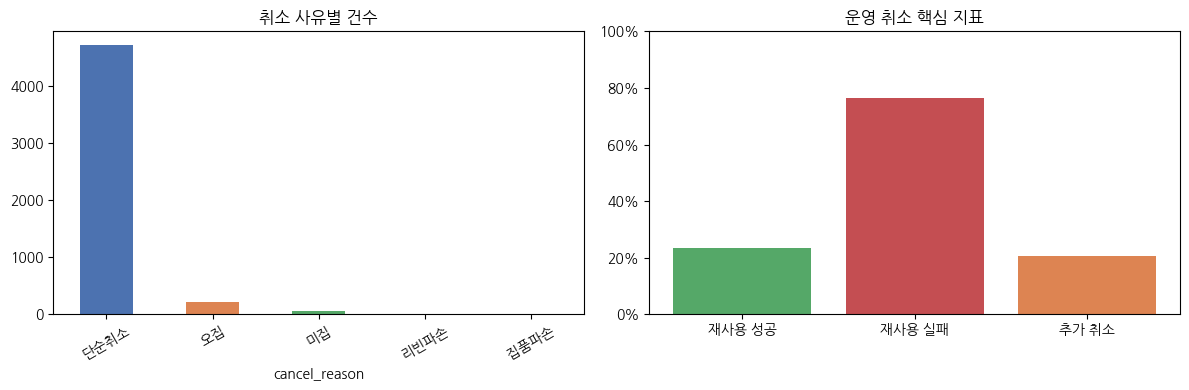

In [ ]:
# =============================================
# STEP 7: 1단계 분석 — 전체 현황
# =============================================

op_df = final_df[final_df['cancel_reason'] != '단순취소']  # 운영취소만

print("=" * 45)
print("1단계. 전체 현황")
print("=" * 45)
print(f"\n전체 취소 건수   : {len(final_df):,}건")
print(f"운영 취소 건수   : {len(op_df):,}건")
print(f"전체 재사용률    : {op_df['reused_flag'].mean():.1%}")
print(f"추가 취소 발생률 : {op_df['additional_cancel_flag'].mean():.1%}")

print("\n[ 취소 사유별 비중 ]")
print(final_df['cancel_reason'].value_counts(normalize=True).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

final_df['cancel_reason'].value_counts().plot(
    kind='bar', ax=axes[0], color=['#4C72B0','#DD8452','#55A868','#C44E52','#9467BD']
)
axes[0].set_title('취소 사유별 건수')
axes[0].tick_params(axis='x', rotation=30)

reuse_rate    = op_df['reused_flag'].mean()
add_can_rate  = op_df['additional_cancel_flag'].mean()
axes[1].bar(['재사용 성공', '재사용 실패', '추가 취소'],
            [reuse_rate, 1-reuse_rate, add_can_rate],
            color=['#55A868','#C44E52','#DD8452'])
axes[1].set_title('운영 취소 핵심 지표')
axes[1].set_ylim(0, 1)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.tight_layout()
plt.show()

## **STEP8 - 2단계 분석**

2단계. 지연 분석

[ 지연 구간별 재사용률 ]
delay_bin
0-10      0.391
10-20     0.458
20-30     0.227
30-50     0.254
50-70     0.231
70-100    0.128
Name: reused_flag, dtype: float64

30분 이하 재사용률: 36.2%
30분 초과 재사용률: 19.1%  (차이: 17.1%p)


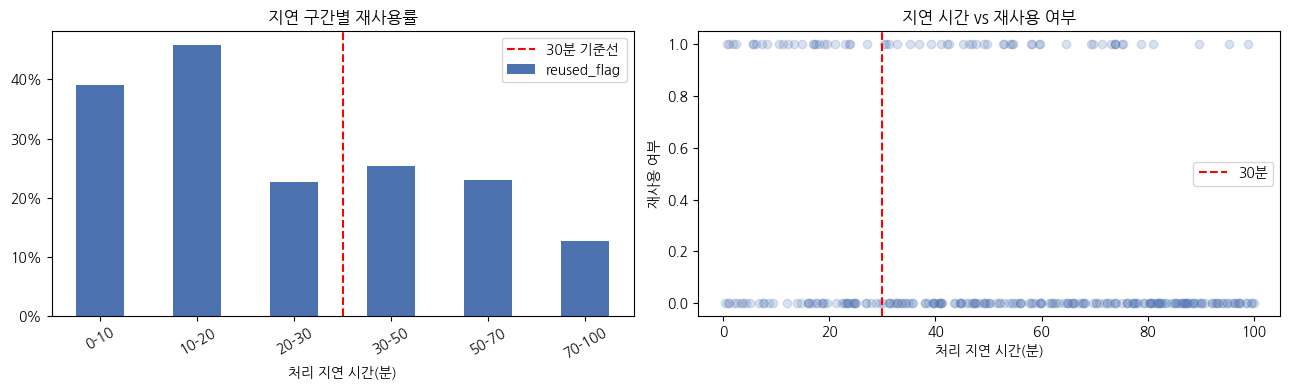

In [ ]:
# =============================================
# STEP 8: 2단계 분석 — 지연 분석
# =============================================

bins   = [0, 10, 20, 30, 50, 70, 100]
labels = ['0-10', '10-20', '20-30', '30-50', '50-70', '70-100']
op_df  = op_df.copy()
op_df['delay_bin'] = pd.cut(op_df['process_delay_min'], bins=bins, labels=labels)

delay_summary = op_df.groupby('delay_bin', observed=True)['reused_flag'].mean()

over  = op_df[op_df['process_delay_min'] >  DELAY_THRESHOLD_MIN]['reused_flag'].mean()
under = op_df[op_df['process_delay_min'] <= DELAY_THRESHOLD_MIN]['reused_flag'].mean()

print("=" * 45)
print("2단계. 지연 분석")
print("=" * 45)
print("\n[ 지연 구간별 재사용률 ]")
print(delay_summary.round(3))
print(f"\n30분 이하 재사용률: {under:.1%}")
print(f"30분 초과 재사용률: {over:.1%}  (차이: {under-over:.1%}p)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

delay_summary.plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].axvline(x=2.5, color='red', linestyle='--', label='30분 기준선')
axes[0].set_title('지연 구간별 재사용률')
axes[0].set_xlabel('처리 지연 시간(분)')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend()

axes[1].scatter(op_df['process_delay_min'], op_df['reused_flag'],
                alpha=0.2, color='#4C72B0')
axes[1].axvline(x=DELAY_THRESHOLD_MIN, color='red', linestyle='--', label='30분')
axes[1].set_title('지연 시간 vs 재사용 여부')
axes[1].set_xlabel('처리 지연 시간(분)')
axes[1].set_ylabel('재사용 여부')
axes[1].legend()

plt.tight_layout()
plt.show()

## **STEP8 - 3단계 분석**

3단계. 사유 분석 (운영 취소 기준)

[ 사유별 재사용률 ]
cancel_reason
리빈파손    0.000
미집      0.053
오집      0.288
집품파손    0.000
Name: reused_flag, dtype: float64

[ 사유별 추가 취소율 ]
cancel_reason
리빈파손    0.000
미집      0.404
오집      0.158
집품파손    0.000
Name: additional_cancel_flag, dtype: float64

▶ 오집 상세
  건수             : 215건
  검수 통과율      : 0.0%
  재사용률         : 28.8%
  추가 취소 발생률 : 15.8%

▶ 미집 상세
  건수               : 57건
  대체 재사용률      : 5.3%
  추가 취소 발생률   : 40.4%


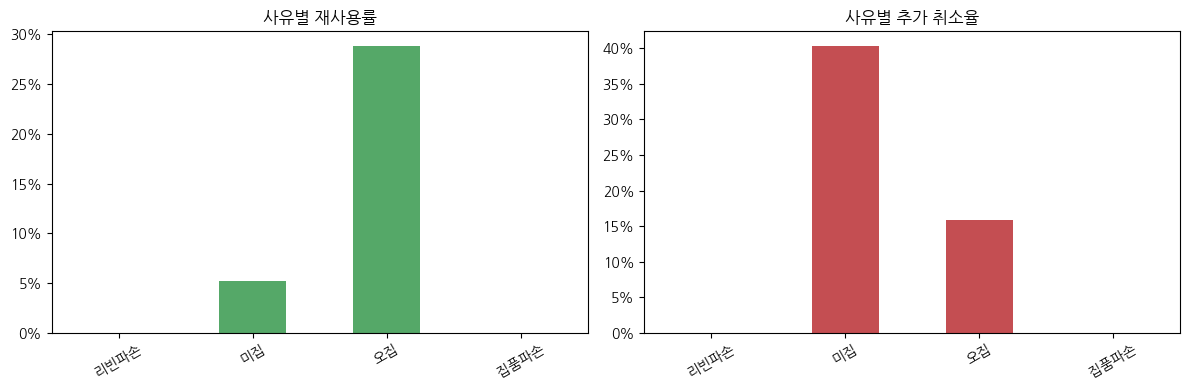

In [ ]:
# =============================================
# STEP 9: 3단계 분석 — 사유 분석
# =============================================

reason_reuse  = op_df.groupby('cancel_reason')['reused_flag'].mean()
reason_addcan = op_df.groupby('cancel_reason')['additional_cancel_flag'].mean()

print("=" * 45)
print("3단계. 사유 분석 (운영 취소 기준)")
print("=" * 45)
print("\n[ 사유별 재사용률 ]")
print(reason_reuse.round(3))
print("\n[ 사유별 추가 취소율 ]")
print(reason_addcan.round(3))

# 오집 상세
wp = op_df[op_df['cancel_reason'] == '오집']
print(f"\n▶ 오집 상세")
print(f"  건수             : {len(wp):,}건")
print(f"  검수 통과율      : {wp['inspection_flag'].mean():.1%}")
print(f"  재사용률         : {wp['reused_flag'].mean():.1%}")
print(f"  추가 취소 발생률 : {wp['additional_cancel_flag'].mean():.1%}")

# 미집 상세
mp = op_df[op_df['cancel_reason'] == '미집']
print(f"\n▶ 미집 상세")
print(f"  건수               : {len(mp):,}건")
print(f"  대체 재사용률      : {mp['reused_flag'].mean():.1%}")
print(f"  추가 취소 발생률   : {mp['additional_cancel_flag'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

reason_reuse.plot(kind='bar', ax=axes[0], color='#55A868')
axes[0].set_title('사유별 재사용률')
axes[0].set_xlabel('')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[0].tick_params(axis='x', rotation=30)

reason_addcan.plot(kind='bar', ax=axes[1], color='#C44E52')
axes[1].set_title('사유별 추가 취소율')
axes[1].set_xlabel('')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## **STEP10 - 4단계 분석**

4단계. 카테고리 분석

[ 카테고리별 운영 취소 건수 ]
category
가공식품    87
채소      62
과일      51
우유      40
축산      38
Name: cancel_reason, dtype: int64

[ 카테고리별 재사용률 ]
category
가공식품    0.402
과일      0.216
우유      0.200
축산      0.132
채소      0.097
Name: reused_flag, dtype: float64

[ 카테고리별 추가 취소율 ]
category
과일      0.255
축산      0.237
채소      0.226
우유      0.200
가공식품    0.149
Name: additional_cancel_flag, dtype: float64


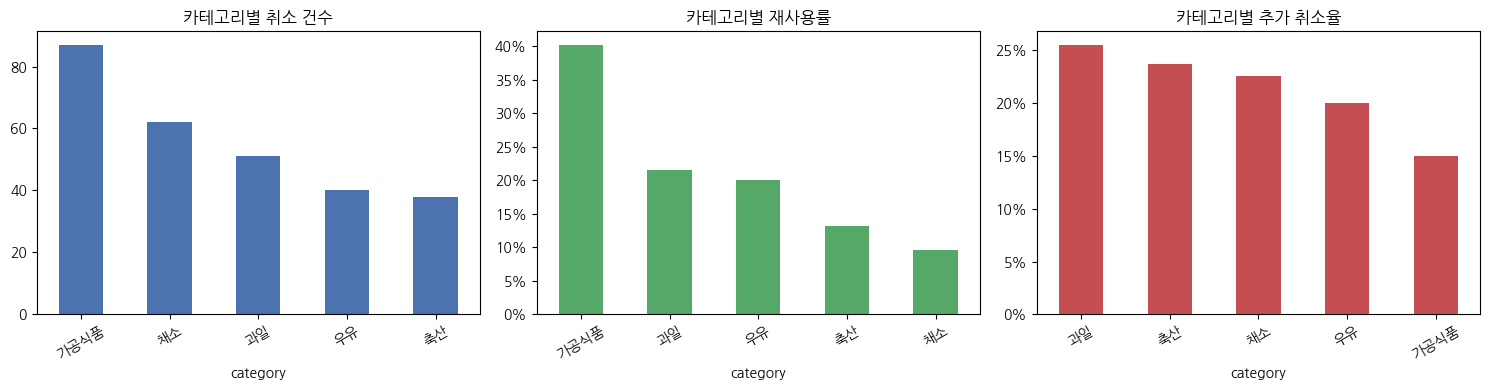

In [ ]:
# =============================================
# STEP 10: 4단계 분석 — 카테고리 분석
# =============================================

cat_count  = op_df.groupby('category')['cancel_reason'].count().sort_values(ascending=False)
cat_reuse  = op_df.groupby('category')['reused_flag'].mean().sort_values(ascending=False)
cat_addcan = op_df.groupby('category')['additional_cancel_flag'].mean().sort_values(ascending=False)

print("=" * 45)
print("4단계. 카테고리 분석")
print("=" * 45)
print("\n[ 카테고리별 운영 취소 건수 ]")
print(cat_count)
print("\n[ 카테고리별 재사용률 ]")
print(cat_reuse.round(3))
print("\n[ 카테고리별 추가 취소율 ]")
print(cat_addcan.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cat_count.plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('카테고리별 취소 건수')
axes[0].tick_params(axis='x', rotation=30)

cat_reuse.plot(kind='bar', ax=axes[1], color='#55A868')
axes[1].set_title('카테고리별 재사용률')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[1].tick_params(axis='x', rotation=30)

cat_addcan.plot(kind='bar', ax=axes[2], color='#C44E52')
axes[2].set_title('카테고리별 추가 취소율')
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## **STEP11 - 5단계 분석**

5단계. 운영 개선 시뮬레이션 (수동 vs 자동화)
         지표 수동 처리 (기존) 자동화 처리 (개선)
       재사용률      23.4%       31.3%
     추가 취소율      20.5%       25.2%
평균 탐색 시간(분)       2.41        0.62
평균 처리 지연(분)       52.8        14.8

처리 속도 비교 (수동 vs 자동화)
  수동 처리   : 60분당 120건   / 건당 0.5분
  자동화 처리 : 60분당 400건   / 건당 0.15분
  처리 속도 향상 : 3.3배
  건당 처리 시간 단축 : 0.35분 절감


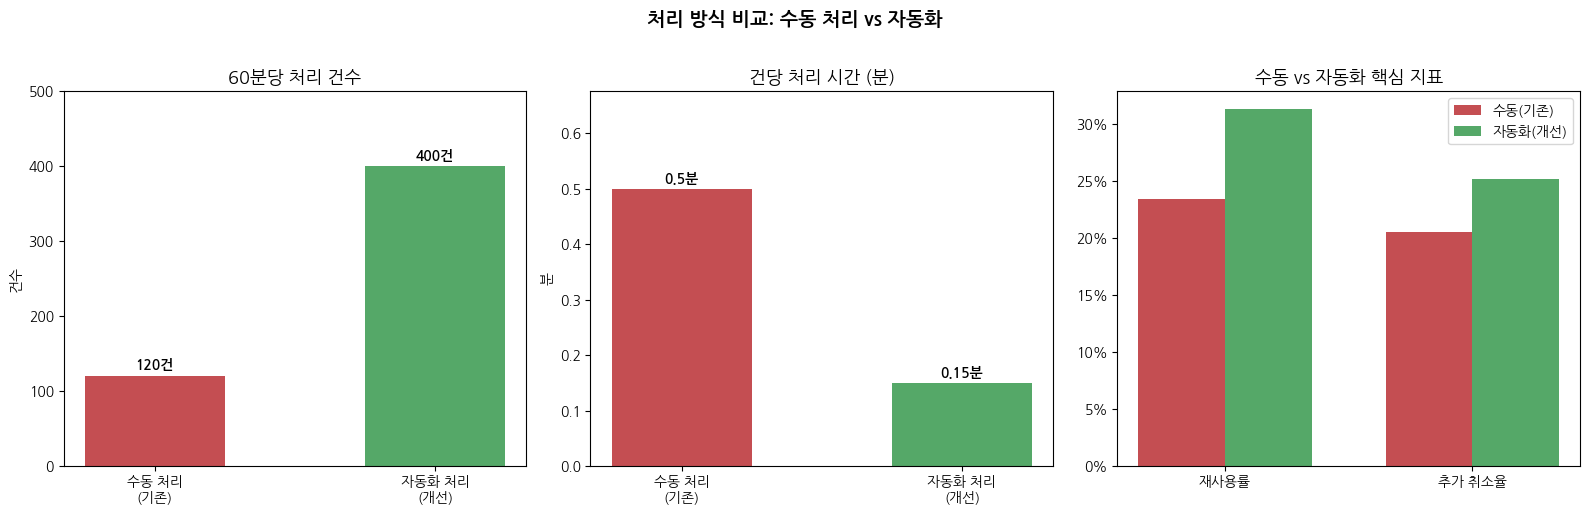

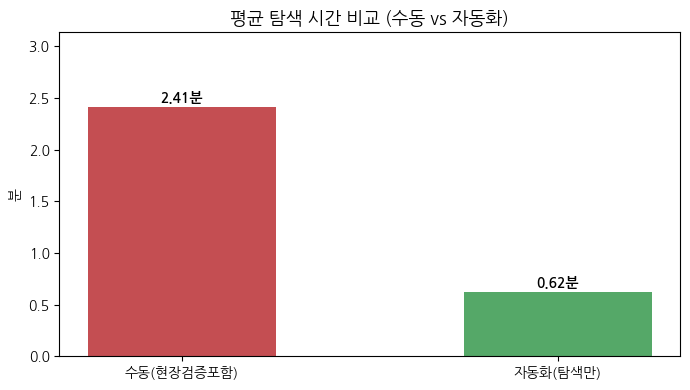

In [ ]:
# =============================================
# STEP 11: 5단계 분석 — 운영 개선 시뮬레이션
# =============================================

improved_df = op_df.copy()

# ==========================================================
# [수정] process_type 컬럼 — 자동화 처리 방식으로 설정
# ==========================================================
improved_df['process_type'] = 'automated'

# 개선 가정 1: 처리 지연 0~30분으로 단축 (자동화로 처리 속도 향상)
# TODO: 실제 개선 목표 수치로 교체
improved_df['process_delay_min'] = np.random.uniform(0, 30, len(improved_df)).round(1)

# 개선 가정 2: 전산화로 위치 정보 확인 가능 비율 60% → 95%
# TODO: 실제 전산화 목표 비율로 교체
improved_df['location_known'] = [
    1 if random.random() < 0.95 else 0
    for _ in range(len(improved_df))
]

# ==========================================================
# [수정] inspection_flag 재계산 — 자동화에서는 별도 검수 단계 복원
# - 수동(기존): inspection 없음 (탐색 현장에서 직접 확인)
# - 자동화(개선): 별도 검수 단계 → 85% 통과율 적용
# ==========================================================
def inspection_improved(row):
    if row['cancel_reason'] != '오집':
        return 0
    if row['restock_flag'] == 0:
        return 0
    # TODO: 검수 통과율 85% → 실제 수치로 교체
    return 1 if random.random() < 0.85 else 0

improved_df['inspection_flag'] = improved_df.apply(inspection_improved, axis=1)

# 개선 후 재사용률 재계산
# ==========================================================
# [수정] reuse_improved — 자동화 처리이므로 inspection_flag 체크 복원
# ==========================================================
def reuse_improved(row):
    if row['cancel_reason'] in ['단순취소', '집품파손', '리빈파손']:
        return 0
    if row['cancel_reason'] == '오집':
        # [수정] 자동화: inspection_flag 통과 여부 확인
        if row['inspection_flag'] == 0:
            return 0
        base = REUSE_PROB.get(row['category'], 0.50)
        if row['process_delay_min'] > DELAY_THRESHOLD_MIN:
            base *= 0.60
        return 1 if random.random() < base else 0
    if row['cancel_reason'] == '미집':
        matched = wrong_pick_pool[
            (wrong_pick_pool['product_id'] == row['product_id']) &
            (wrong_pick_pool['sku_option'] == row['sku_option'])
        ]
        if len(matched) == 0:
            return 0
        base = 0.70 if row['process_delay_min'] <= DELAY_THRESHOLD_MIN else 0.30
        return 1 if random.random() < base else 0
    return 0

def add_cancel_improved(row):
    if row['cancel_reason'] == '단순취소' or row['reused_flag'] == 1:
        return 0
    if row['cancel_reason'] == '오집':
        prob = 0.25
    elif row['cancel_reason'] == '미집':
        prob = 0.40
    else:
        prob = 0.10
    return 1 if random.random() < prob else 0

# ==========================================================
# [수정] search_improved — 자동화 처리: 탐색 시간만 반영 (현장 검증 딜레이 제외)
#        (inspection이 별도 단계로 분리되었으므로 탐색 순수 시간만)
# ==========================================================
def search_improved(row):
    if row['cancel_reason'] == '오집' and row['restock_flag'] == 1:
        pass
    elif row['cancel_reason'] == '미집' and row['reused_flag'] == 1:
        pass
    else:
        return None
    # [수정] 자동화: 현장 검증 딜레이 없이 순수 탐색 시간만 계산
    return round(random.uniform(0, 1), 1) if row['location_known'] \
           else round(random.uniform(1, 3), 1)

improved_df['reused_flag']            = improved_df.apply(reuse_improved, axis=1)
improved_df['additional_cancel_flag'] = improved_df.apply(add_cancel_improved, axis=1)
improved_df['search_time_min']        = improved_df.apply(search_improved, axis=1)

# ── 개선 전/후 비교 테이블 ────────────────────
before = op_df
after  = improved_df

compare = pd.DataFrame({
    '지표': ['재사용률', '추가 취소율', '평균 탐색 시간(분)', '평균 처리 지연(분)'],
    '수동 처리 (기존)': [
        f"{before['reused_flag'].mean():.1%}",
        f"{before['additional_cancel_flag'].mean():.1%}",
        f"{before['search_time_min'].mean():.2f}",
        f"{before['process_delay_min'].mean():.1f}",
    ],
    '자동화 처리 (개선)': [
        f"{after['reused_flag'].mean():.1%}",
        f"{after['additional_cancel_flag'].mean():.1%}",
        f"{after['search_time_min'].mean():.2f}",
        f"{after['process_delay_min'].mean():.1f}",
    ],
})

print("=" * 55)
print("5단계. 운영 개선 시뮬레이션 (수동 vs 자동화)")
print("=" * 55)
print(compare.to_string(index=False))

# ==========================================================
# [수정] 처리 속도 차이 지표 출력 및 시각화
# - 수동 : 60분당 120건 / 건당 0.5분
# - 자동화: 60분당 400건 / 건당 0.15분
# ==========================================================
print("\n" + "=" * 55)
print("처리 속도 비교 (수동 vs 자동화)")
print("=" * 55)
print(f"  수동 처리   : 60분당 {MANUAL_THROUGHPUT}건   / 건당 {MANUAL_TIME_PER_CASE}분")
print(f"  자동화 처리 : 60분당 {AUTOMATED_THROUGHPUT}건   / 건당 {AUTOMATED_TIME_PER_CASE}분")
print(f"  처리 속도 향상 : {AUTOMATED_THROUGHPUT / MANUAL_THROUGHPUT:.1f}배")
print(f"  건당 처리 시간 단축 : {MANUAL_TIME_PER_CASE - AUTOMATED_TIME_PER_CASE:.2f}분 절감")

# ── 시각화 ────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 차트 1: 처리 속도 비교 (60분당 처리 건수)
speed_labels = ['수동 처리\n(기존)', '자동화 처리\n(개선)']
speed_vals   = [MANUAL_THROUGHPUT, AUTOMATED_THROUGHPUT]
bars = axes[0].bar(speed_labels, speed_vals, color=['#C44E52', '#55A868'], width=0.5)
axes[0].set_title('60분당 처리 건수', fontsize=13)
axes[0].set_ylabel('건수')
for bar, val in zip(bars, speed_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'{val}건', ha='center', va='bottom', fontweight='bold')
axes[0].set_ylim(0, max(speed_vals) * 1.25)

# 차트 2: 건당 처리 시간 비교
time_vals = [MANUAL_TIME_PER_CASE, AUTOMATED_TIME_PER_CASE]
bars2 = axes[1].bar(speed_labels, time_vals, color=['#C44E52', '#55A868'], width=0.5)
axes[1].set_title('건당 처리 시간 (분)', fontsize=13)
axes[1].set_ylabel('분')
for bar, val in zip(bars2, time_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{val}분', ha='center', va='bottom', fontweight='bold')
axes[1].set_ylim(0, max(time_vals) * 1.35)

# 차트 3: 개선 전/후 핵심 지표 그룹 비교
metrics = ['재사용률', '추가 취소율']
before_vals = [before['reused_flag'].mean(), before['additional_cancel_flag'].mean()]
after_vals  = [after['reused_flag'].mean(),  after['additional_cancel_flag'].mean()]
x = range(len(metrics))
w = 0.35
axes[2].bar([i - w/2 for i in x], before_vals, width=w, label='수동(기존)', color='#C44E52')
axes[2].bar([i + w/2 for i in x], after_vals,  width=w, label='자동화(개선)', color='#55A868')
axes[2].set_title('수동 vs 자동화 핵심 지표', fontsize=13)
axes[2].set_xticks(list(x))
axes[2].set_xticklabels(metrics)
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[2].legend()

plt.suptitle('처리 방식 비교: 수동 처리 vs 자동화', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 추가: 평균 탐색 시간 비교 (수동 현장검증 포함 vs 자동화 탐색만)
fig2, ax = plt.subplots(figsize=(7, 4))
search_labels = ['수동(현장검증포함)', '자동화(탐색만)']
search_vals = [
    before['search_time_min'].dropna().mean(),
    after['search_time_min'].dropna().mean()
]
bars3 = ax.bar(search_labels, search_vals, color=['#C44E52', '#55A868'], width=0.5)
ax.set_title('평균 탐색 시간 비교 (수동 vs 자동화)', fontsize=13)
ax.set_ylabel('분')
for bar, val in zip(bars3, search_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{val:.2f}분', ha='center', va='bottom', fontweight='bold')
ax.set_ylim(0, max(search_vals) * 1.3)
plt.tight_layout()
plt.show()


## **STEP12 - 저장**

In [ ]:
# =============================================
# STEP 12: 저장
# =============================================
from google.colab import drive
drive.mount('/content/drive')

import os
PATH = '/content/drive/MyDrive/logistics_simulation/'
# TODO: 원하는 드라이브 경로로 변경
os.makedirs(PATH, exist_ok=True)

final_df.to_csv(PATH + 'simulation_data.csv',       index=False, encoding='utf-8-sig')
improved_df.to_csv(PATH + 'simulation_improved.csv', index=False, encoding='utf-8-sig')
print(f"저장 완료 → {PATH}")
print(f"simulation_data.csv    : {len(final_df):,}행")
print(f"simulation_improved.csv: {len(improved_df):,}행")

Mounted at /content/drive
저장 완료 → /content/drive/MyDrive/logistics_simulation/
simulation_data.csv    : 5,000행
simulation_improved.csv: 278행


**시뮬레이션 데이터 기반이며 실제 운영 데이터 적용 시 수치는 달라질 수 있다**